In [16]:
! pip install tensorflow



In [17]:
import tensorflow as tf

In [18]:
import tensorflow as tf
import matplotlib.pyplot as plt
# import pandas as pd
# import seaborn as sns

In [19]:
import os
print("Current Working Directory: ", os.getcwd())

Current Working Directory:  c:\Users\anush\OneDrive\Documents\AICW\plant_leaf_disease_detection


In [20]:
#import os
#print("Current Working Directory: ", os.getcwd())
current_directory = os.getcwd()
train_path = os.path.join(current_directory,"archive","data","Training")
test_path = os.path.join(current_directory,"archive","data","Testing")
valid_path = os.path.join(current_directory,"archive","data","Validation")

In [21]:
train_path

'c:\\Users\\anush\\OneDrive\\Documents\\AICW\\plant_leaf_disease_detection\\archive\\data\\Training'

In [22]:
test_path


'c:\\Users\\anush\\OneDrive\\Documents\\AICW\\plant_leaf_disease_detection\\archive\\data\\Testing'

In [23]:
valid_path

'c:\\Users\\anush\\OneDrive\\Documents\\AICW\\plant_leaf_disease_detection\\archive\\data\\Validation'

In [24]:
! pip install keras

In [25]:
training_set = tf.keras.utils.image_dataset_from_directory(
    train_path,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    interpolation="bilinear",
)

Found 3251 files belonging to 3 classes.


In [35]:
validation_set = tf.keras.utils.image_dataset_from_directory(
    valid_path,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    interpolation="bilinear",
)

Found 416 files belonging to 3 classes.


In [27]:
cnn = tf.keras.models.Sequential()

cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Dropout(0.25))

cnn.add(tf.keras.layers.Flatten())
cnn.add(tf.keras.layers.Dense(units=1500,activation='relu'))
cnn.add(tf.keras.layers.Dropout(0.4))

cnn.add(tf.keras.layers.Dense(units=3,activation='softmax'))

c:\Users\anush\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [28]:
cnn.compile(optimizer=tf.keras.optimizers.Adam(
    learning_rate=0.0001),loss='categorical_crossentropy',metrics=['accuracy'])

In [29]:
cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 126, 126, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 63, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 61, 61, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 30, 30, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 14, 14, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1500)           │     3,073,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │         4,503 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,790,227 (29.72 MB)

 Trainable params: 7,790,227 (29.72 MB)

 Non-trainable params: 0 (0.00 B)

In [36]:
training_history = cnn.fit(x=training_set,validation_data=validation_set,epochs=10)

Epoch 1/10


c:\Users\anush\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 601ms/step - accuracy: 0.4062 - loss: 1.1560 - val_accuracy: 0.4928 - val_loss: 1.0200
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 553ms/step - accuracy: 0.4856 - loss: 1.0125 - val_accuracy: 0.5168 - val_loss: 0.9922
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 894ms/step - accuracy: 0.5505 - loss: 0.9672 - val_accuracy: 0.6514 - val_loss: 0.8492
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 923ms/step - accuracy: 0.6370 - loss: 0.8748 - val_accuracy: 0.6683 - val_loss: 0.7968
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.6322 - loss: 0.8641 - val_accuracy: 0.7091 - val_loss: 0.7208
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 877ms/step - accuracy: 0.7067 - loss: 0.7349 - val_accuracy: 0.7452 - val_loss: 0.6478
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 901ms/step - accuracy: 0.6947 - loss: 0.6912 - val_accuracy: 0.7091 - val_loss: 0.7376
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 927ms/step - accuracy: 0.6803 - loss: 0.7794 - val_accuracy: 0.7885 - 

In [37]:
vol_loss, val_acc = cnn.evaluate(validation_set)
print('Validation accuracy:', val_acc)

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 129ms/step - accuracy: 0.8438 - loss: 0.4700
Validation accuracy: 0.84375


In [38]:
cnn.save('trained_plant_disease_model.keras')

In [39]:
training_history.history

{'accuracy': [0.40625,
  0.48557692766189575,
  0.5504807829856873,
  0.6370192170143127,
  0.6322115659713745,
  0.7067307829856873,
  0.6947115659713745,
  0.6802884340286255,
  0.7331730723381042,
  0.7692307829856873],
 'loss': [1.1559743881225586,
  1.0125253200531006,
  0.9671767354011536,
  0.8747802972793579,
  0.8641042113304138,
  0.7349332571029663,
  0.6911860704421997,
  0.7793607711791992,
  0.6655603051185608,
  0.5968837738037109],
 'val_accuracy': [0.4927884638309479,
  0.5168269276618958,
  0.651442289352417,
  0.6682692170143127,
  0.7091346383094788,
  0.745192289352417,
  0.7091346383094788,
  0.7884615659713745,
  0.7692307829856873,
  0.84375],
 'val_loss': [1.0199536085128784,
  0.9922090172767639,
  0.8491808176040649,
  0.7968274354934692,
  0.7208114266395569,
  0.6477884650230408,
  0.7376375198364258,
  0.6428412795066833,
  0.5603020787239075,
  0.4700267016887665]}

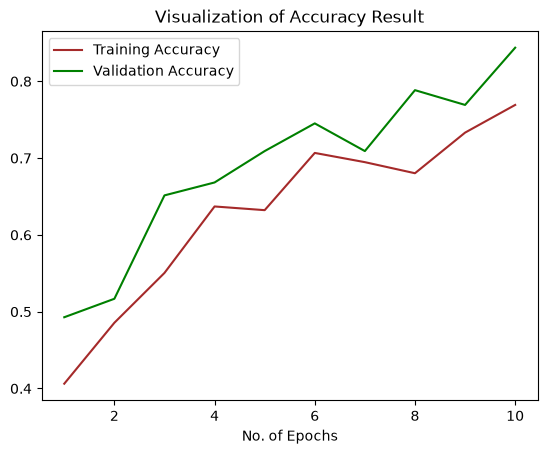

In [41]:
epochs = [i for i in range(1,11)]
plt.plot(epochs,training_history.history['accuracy'],color='brown',label='Training Accuracy')
plt.plot(epochs,training_history.history['val_accuracy'],color='green',label='Validation Accuracy')
plt.xlabel('No. of Epochs')
plt.title('Visualization of Accuracy Result')
plt.legend()
plt.show()